<h1>Lab01 — sprint 2</h1>
<h2>Второй алгоритм: отбор с отклонением</h2>
<h3>Description</h3>

Оставляем распределение качества при крепости 12% об. и k = 720. Меняем только способ генерации.
Выбираем один из возможных баллов равновероятно. Частые баллы принимаем чаще, редкие — реже; отклонённую попытку повторяем.
Модель обучена на train. Test не используем.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file())
sys.path.insert(0,str(ROOT/'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.generator import quality_distribution, inverse_cdf
meta=json.loads((ROOT/'data/processed/alcohol_quality_split.json').read_text())
for name,info in meta['files'].items():
    assert hashlib.sha256((ROOT/'data/raw'/name).read_bytes()).hexdigest()==info['sha256']
df=load_wines(ROOT/'data/raw')
manifest=pd.read_csv(ROOT/'data/processed/alcohol_quality_split.csv')
pd.testing.assert_frame_equal(manifest,split_wines(df,seed=42))
assert manifest.groupby('group_id')['split'].nunique().max()==1
train=df.loc[manifest['split'].eq('train')]

values,p=quality_distribution(train.alcohol,train.quality,12.,k=720)
mu=values@p
variance=((values-mu)**2)@p
moment4=((values-mu)**4)@p
print(f'Среднее модели: {mu:.6f}; дисперсия: {variance:.6f}')

from wine_stats.generator import rejection_sample
from time import perf_counter


Среднее модели: 6.375315; дисперсия: 0.670222


<h3>math desc</h3>

Пусть m — число предложенных баллов, а p_j — вероятность j-го балла в модели. Выбираем индекс J равномерно и независимо U из [0, 1). Принимаем балл, если U < p_J/p_max.

Вероятность предложить и принять конкретный балл:

$$
P(J=j, A)=\frac{1}{m}\frac{p_j}{p_{\max}}.
$$

Суммируем по баллам и получаем вероятность принятия одной попытки:

$$
P(A)=\frac{1}{m p_{\max}}.
$$

Среди принятых попыток вероятность балла j равна именно требуемой:

$$
P(J=j\mid A)=\frac{P(J=j,A)}{P(A)}=p_j.
$$

Число попыток до принятия имеет геометрическое распределение, поэтому в среднем на одну оценку нужно m·p_max попыток. Чем сильнее вероятности различаются, тем больше отклонений. Вероятность ноль означает, что балл никогда не принимается.

Метод работает и для непрерывных распределений при подходящей мажоранте. Здесь достаточно равномерного предложения на конечном наборе баллов.

Источник: Luc Devroye, *Non-Uniform Random Variate Generation*, Springer, 1986, глава II, §3, с. 40–43. [Книга автора](https://luc.devroye.org/LucDevroye-NonUniformRandomVariateGeneration-10.1007_978-1-4613-8643-8-1986.pdf).

<h3>code</h3>

Реализация находится в src/wine_stats/generator.py. Функция возвращает выборку и число попыток. Все принятые значения сохраняются; в конце пакета лишних принятых значений нет. Оба метода используют NumPy для базовой псевдослучайной последовательности.

In [2]:
n=100000
inverse=inverse_cdf(values,p,np.random.default_rng(42).random(n))
rejected,attempts=rejection_sample(values,p,n,seed=42)
frequency=pd.DataFrame({'quality':values,'model':p,
    'inverse_cdf':[(inverse==v).mean() for v in values],
    'rejection':[(rejected==v).mean() for v in values]})
metrics=pd.DataFrame([
    {'method':name,'mean':a.mean(),'variance':a.var(),
     'tv_to_model':.5*np.abs(np.array([(a==v).mean() for v in values])-p).sum()}
    for name,a in [('inverse_cdf',inverse),('rejection',rejected)]])
display(frequency.round(5));display(metrics.round(6))
print(f'Принято {n} из {attempts} попыток: {n/attempts:.2%}')
print(f'Теоретическая доля принятия: {1/(len(p)*p.max()):.2%}')
frequency.to_csv(ROOT/'reports/tables/generator_methods_frequencies.csv',index=False)
metrics.to_csv(ROOT/'reports/tables/generator_methods_metrics.csv',index=False)


Принято 100000 из 352088 попыток: 28.40%
Теоретическая доля принятия: 28.29%


,quality,model,inverse_cdf,rejection
0,3,0.00252,0.00253,0.00253
1,4,0.01385,0.01414,0.01331
2,5,0.07557,0.07493,0.07523
3,6,0.50504,0.50344,0.50524
4,7,0.32242,0.32386,0.32170
5,8,0.07809,0.07848,0.07932
6,9,0.00252,0.00262,0.00267


,method,mean,variance,tv_to_model
0,inverse_cdf,6.37788,0.672827,0.002235
1,rejection,6.37891,0.670677,0.001599


<h3>tests — частоты и скорость</h3>

Совпадения отдельных последовательностей не ожидаем: алгоритмы расходуют случайные числа по-разному.
Скорость измеряем после одного прогрева, по медиане 15 запусков, чередуя порядок методов. Включаем генерацию базовых случайных чисел, но не поиск соседей — распределение уже зафиксировано. Это время наших реализаций на данной машине, а не универсальный рейтинг алгоритмов.

,method,n,median_ms,q25_ms,q75_ms
0,inverse_cdf,100000,1.919,1.904,1.936
1,rejection,100000,4.293,4.202,4.401


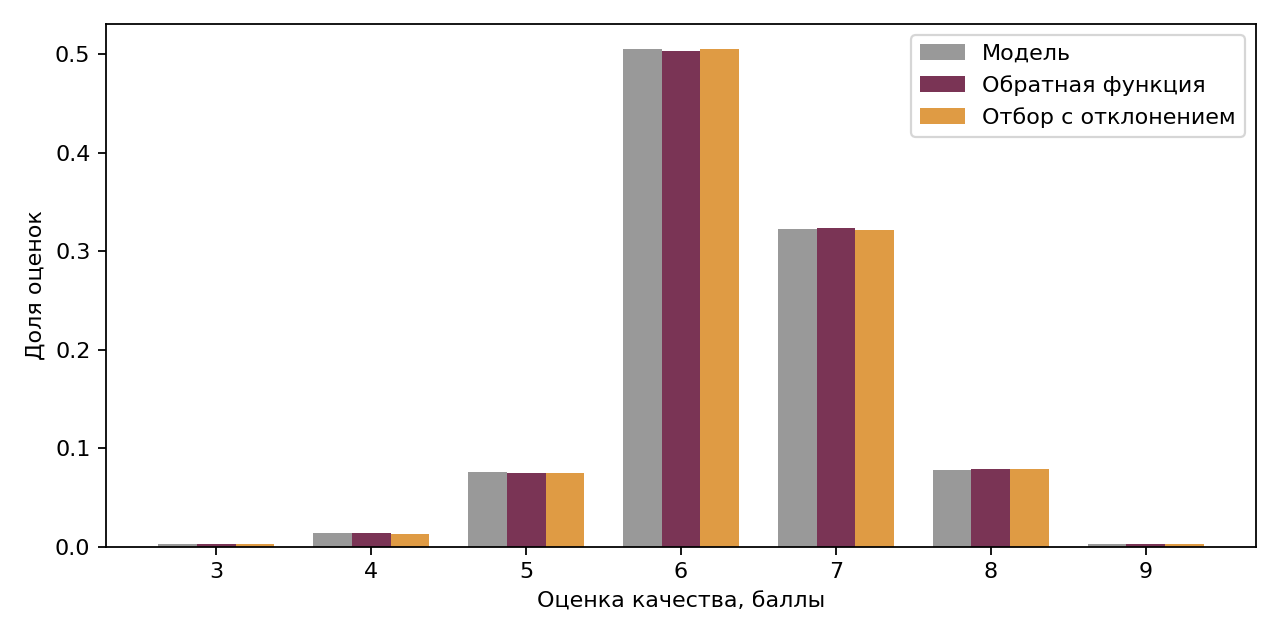

In [3]:
timings={'inverse_cdf':[],'rejection':[]}
def run_method(name,seed):
    if name=='inverse_cdf':
        return inverse_cdf(values,p,np.random.default_rng(seed).random(n))
    return rejection_sample(values,p,n,seed=seed)[0]
for name in timings:run_method(name,0)
for repeat in range(15):
    order=list(timings) if repeat%2==0 else list(reversed(timings))
    for name in order:
        start=perf_counter()
        run_method(name,100+repeat)
        timings[name].append(1000*(perf_counter()-start))
benchmark=pd.DataFrame([{'method':name,'n':n,'median_ms':np.median(t),
    'q25_ms':np.quantile(t,.25),'q75_ms':np.quantile(t,.75)} for name,t in timings.items()])
display(benchmark.round(3))
benchmark.to_csv(ROOT/'reports/tables/generator_methods_timing.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
x=np.arange(len(values));w=.25
for offset,col,label,color in [(-w,'model','Модель','#999999'),(0,'inverse_cdf','Обратная функция','#7a3455'),(w,'rejection','Отбор с отклонением','#df9b44')]:
    ax.bar(x+offset,frequency[col],width=w,label=label,color=color)
ax.set(xticks=x,xticklabels=values,xlabel='Оценка качества, баллы',ylabel='Доля оценок')
ax.legend();fig.tight_layout()
path=ROOT/'reports/figures/generator_methods.png'
fig.savefig(path,dpi=160);plt.close(fig);display(Image(filename=str(path)))


<h3>resume</h3>

Для 100 000 оценок расстояние полной вариации до заданного распределения составило 0.00223 у обратной функции и 0.00160 у отбора с отклонением. Это ошибки двух конечных выборок, а не доказательство превосходства одного метода.

Принято 28.40% попыток при теоретических 28.29%. Медианное время составило 1.92 и 4.29 мс соответственно.

Оба метода генерируют одно и то же распределение. Для нашей короткой таблицы вероятностей оставляем обратную функцию основной: она не тратит попытки на отклонения. Отбор полезен как альтернативный подход, когда легко найти предложение и ограничить отношение вероятностей, а обращать функцию распределения неудобно.

Автотесты проверяют частоты, нулевые вероятности, вырожденный случай, пустую выборку, воспроизводимость и неверные параметры (tests/test_rejection.py).